In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Data preparation

In [2]:
df = pd.read_csv("wdbc.data", header = None)

In [3]:
columns = [
    "id", "diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean",
    "area_mean", "smoothness_mean", "compactness_mean",
    "concavity_mean", "concave_points_mean", "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se",
    "area_se", "smoothness_se", "compactness_se",
    "concavity_se", "concave_points_se", "symmetry_se",
    "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst",
    "area_worst", "smoothness_worst", "compactness_worst",
    "concavity_worst", "concave_points_worst", "symmetry_worst",
    "fractal_dimension_worst"
]

df.columns = columns

In [4]:
df.head().T

,0,1,2,3,4
id,842302,842517,84300903,84348301,84358402
diagnosis,M,M,M,M,M
radius_mean,17.99,20.57,19.69,11.42,20.29
texture_mean,10.38,17.77,21.25,20.38,14.34
perimeter_mean,122.8,132.9,130.0,77.58,135.1
area_mean,1001.0,1326.0,1203.0,386.1,1297.0
smoothness_mean,0.1184,0.08474,0.1096,0.1425,0.1003
compactness_mean,0.2776,0.07864,0.1599,0.2839,0.1328
concavity_mean,0.3001,0.0869,0.1974,0.2414,0.198
concave_points_mean,0.1471,0.07017,0.1279,0.1052,0.1043


In [5]:
df.shape

(569, 32)

In [6]:
df.columns.to_series().groupby(df.dtypes.astype(str)).apply(list)

float64    [radius_mean, texture_mean, perimeter_mean, ar...
int64                                                   [id]
str                                              [diagnosis]
dtype: object

### Making diagnosis values uniform

In [7]:
df['diagnosis'] = df['diagnosis'].str.lower()

In [8]:
df.head().T

,0,1,2,3,4
id,842302,842517,84300903,84348301,84358402
diagnosis,m,m,m,m,m
radius_mean,17.99,20.57,19.69,11.42,20.29
texture_mean,10.38,17.77,21.25,20.38,14.34
perimeter_mean,122.8,132.9,130.0,77.58,135.1
area_mean,1001.0,1326.0,1203.0,386.1,1297.0
smoothness_mean,0.1184,0.08474,0.1096,0.1425,0.1003
compactness_mean,0.2776,0.07864,0.1599,0.2839,0.1328
concavity_mean,0.3001,0.0869,0.1974,0.2414,0.198
concave_points_mean,0.1471,0.07017,0.1279,0.1052,0.1043


### Encoding the target variable

In [9]:
df.diagnosis.head()

0    m
1    m
2    m
3    m
4    m
Name: diagnosis, dtype: str

In [10]:
df.diagnosis = (df.diagnosis == 'm').astype(int)

In [11]:
df.diagnosis.unique()

array([1, 0])

## Validation framework

In [12]:
from sklearn.model_selection import train_test_split

### Splitting the data

In [13]:
df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state = 1)
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 1)

In [14]:
print(f"Training set lenght: {len(df_train)}, validation set lenght: {len(df_val)}, test set lenght: {len(df_test)}")

Training set lenght: 341, validation set lenght: 114, test set lenght: 114


### Resetting the index

In [15]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

### Isolating the target

In [16]:
y_train = df_train.diagnosis.values
y_val = df_val.diagnosis.values
y_test = df_test.diagnosis.values

y_full_train = df_full_train.diagnosis.values

In [17]:
del df_train['diagnosis']
del df_val['diagnosis']
del df_test['diagnosis']

## Exploratory Data Analysis

### Missing values

In [18]:
df_full_train.isnull().sum()

id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [19]:
df_full_train.isnull().sum().sum() == 0

np.True_

### Diagnosis rate

In [20]:
df_full_train.diagnosis.value_counts(normalize = True)

diagnosis
0    0.626374
1    0.373626
Name: proportion, dtype: float64

### Numerical variables

In [21]:
features = ["radius_mean", "texture_mean", "perimeter_mean",
    "area_mean", "smoothness_mean", "compactness_mean",
    "concavity_mean", "concave_points_mean", "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se",
    "area_se", "smoothness_se", "compactness_se",
    "concavity_se", "concave_points_se", "symmetry_se",
    "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst",
    "area_worst", "smoothness_worst", "compactness_worst",
    "concavity_worst", "concave_points_worst", "symmetry_worst",
    "fractal_dimension_worst"]

## Feature importance

### Correlation

In [22]:
corr = df_full_train[features].corrwith(df_full_train["diagnosis"])
print(corr.abs().sort_values(ascending=False))

concave_points_worst       0.807746
perimeter_worst            0.796377
radius_worst               0.789690
concave_points_mean        0.782401
perimeter_mean             0.758187
radius_mean                0.747875
area_worst                 0.747461
area_mean                  0.726282
concavity_mean             0.713990
concavity_worst            0.698110
compactness_worst          0.617179
compactness_mean           0.616601
radius_se                  0.566516
perimeter_se               0.559625
area_se                    0.546220
texture_worst              0.467918
texture_mean               0.431990
smoothness_worst           0.428088
symmetry_worst             0.427056
concave_points_se          0.415526
smoothness_mean            0.347473
fractal_dimension_worst    0.335302
symmetry_mean              0.324675
compactness_se             0.306263
concavity_se               0.285841
smoothness_se              0.072697
fractal_dimension_se       0.068451
fractal_dimension_mean     0

### Mutual information

In [23]:
from sklearn.feature_selection import mutual_info_classif

In [24]:
mi = mutual_info_classif(df_full_train[features], df_full_train["diagnosis"], random_state=1)
print(pd.Series(mi, index=features).sort_values(ascending=False))

perimeter_worst            0.491594
area_worst                 0.481141
radius_worst               0.471049
concave_points_worst       0.468324
concave_points_mean        0.439382
perimeter_mean             0.426084
concavity_mean             0.402076
radius_mean                0.387774
area_mean                  0.386182
area_se                    0.361871
concavity_worst            0.359170
perimeter_se               0.273234
compactness_worst          0.266499
radius_se                  0.244400
compactness_mean           0.229620
concavity_se               0.125874
texture_worst              0.124172
smoothness_worst           0.118041
concave_points_se          0.117098
texture_mean               0.109648
symmetry_worst             0.092178
compactness_se             0.091590
smoothness_mean            0.079357
fractal_dimension_se       0.059611
fractal_dimension_worst    0.057818
symmetry_mean              0.052475
fractal_dimension_mean     0.010006
smoothness_se              0

## Logistic regression 

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [26]:
X_train = df_train[features]
X_val = df_val[features]
X_full_train = df_full_train[features]

X_test = df_test[features]

In [27]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   
X_val_scaled = scaler.transform(X_val)

X_full_train_scaled = scaler.fit_transform(X_full_train)

X_test_scaled = scaler.transform(X_test)

In [28]:
model = LogisticRegression(solver='lbfgs', max_iter = 1000)
model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [29]:
y_pred_val = model.predict_proba(X_val_scaled)[:, 1]

In [30]:
decision_val = (y_pred_val >= 0.5)
print(f"Decision validation lenght: {len(decision_val)}")
print(f"Accuracy score on validation is: {accuracy_score(y_val, decision_val)}")

Decision validation lenght: 114
Accuracy score on validation is: 0.9824561403508771


In [31]:
model = LogisticRegression(solver='lbfgs', max_iter = 1000)
model.fit(X_full_train_scaled, y_full_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [32]:
y_pred_test = model.predict_proba(X_test_scaled)[:, 1]

In [33]:
decision_test = (y_pred_test >= 0.5)
print(f"Decision test lenght: {len(decision_test)}")
print(f"Accuracy score on test is: {accuracy_score(y_test, decision_test)}")

Decision test lenght: 114
Accuracy score on test is: 0.9736842105263158


## Evaluation metrics for classification

### Accuracy thresholds

In [34]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred_val >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.351
0.05 0.939
0.10 0.965
0.15 0.974
0.20 0.982
0.25 0.991
0.30 0.991
0.35 0.991
0.40 0.991
0.45 0.991
0.50 0.982
0.55 0.974
0.60 0.974
0.65 0.974
0.70 0.965
0.75 0.965
0.80 0.965
0.85 0.965
0.90 0.965
0.95 0.965
1.00 0.658


### Confusion matrix, Precision, Recall, Specificity and F2-score

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [36]:
cm = confusion_matrix(y_val, y_pred_val >= 0.25)
print(cm)

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

[[74  0]
 [ 1 39]]
TN=74, FP=0, FN=1, TP=39


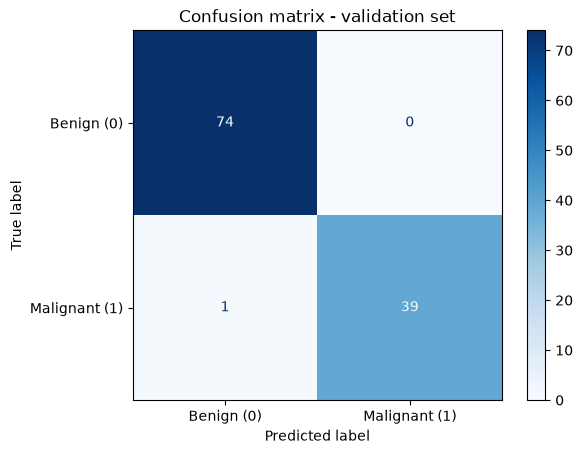

In [37]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign (0)", "Malignant (1)"])
disp.plot(cmap="Blues")
plt.title("Confusion matrix - validation set")
plt.show()

In [38]:
from sklearn.metrics import fbeta_score

precision = tp / (tp + fp)
recall = tp / (tp + fn)
specificity = tn / (tn + fp)

print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"Specificity: {specificity:.3f}")
print(f"F2-score: {fbeta_score(y_val, y_pred_val >= 0.25, beta=2):.3f}")

Precision: 1.000
Recall:    0.975
Specificity: 1.000
F2-score: 0.980


### ROC AUC curve

In [39]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

In [40]:
auc_val = roc_auc_score(y_val, y_pred_val)
print(f"ROC AUC (validation): {auc_val:.3f}")

ROC AUC (validation): 0.999


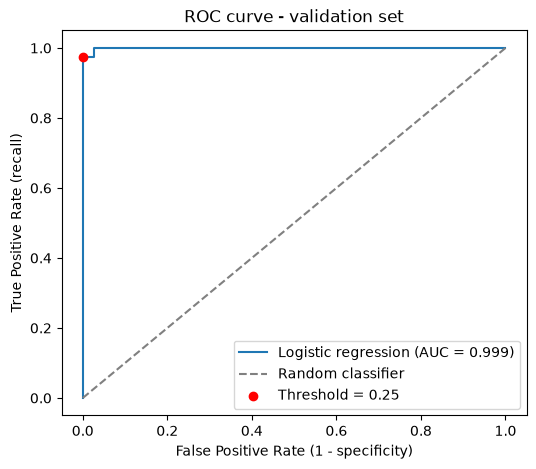

In [41]:
fpr, tpr, thresholds_roc = roc_curve(y_val, y_pred_val)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {auc_val:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.xlabel("False Positive Rate (1 - specificity)")
plt.ylabel("True Positive Rate (recall)")
plt.title("ROC curve - validation set")
idx = (thresholds_roc >= 0.25).sum() - 1
plt.scatter(fpr[idx], tpr[idx], color="red", zorder=5, label="Threshold = 0.25")
plt.legend()
plt.show()

### Cross-validation

In [42]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import make_scorer, classification_report

In [43]:
pipeline = make_pipeline(StandardScaler(), LogisticRegression(solver="lbfgs", max_iter=1000))

In [44]:
kfold = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 1)

In [45]:
scoring = {"roc_auc": "roc_auc", "recall": "recall", "f2": make_scorer(fbeta_score, beta=2)}

In [46]:
param_grid = {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(pipeline, param_grid = param_grid, cv = kfold, scoring = scoring, refit = "roc_auc", return_train_score = False)
grid.fit(X_full_train, y_full_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'f2': make_scorer(f...dict', beta=2), 'recall': 'recall', 'roc_auc': 'roc_auc'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default cha

In [47]:
print("Best parameters:", grid.best_params_)
print(f"Best CV ROC AUC: {grid.best_score_:.3f}")

results = pd.DataFrame(grid.cv_results_)[
    ["param_logisticregression__C",
     "mean_test_roc_auc", "std_test_roc_auc",
     "mean_test_recall", "mean_test_f2"]
]
print(results.round(3).to_string(index=False))

Best parameters: {'logisticregression__C': 1}
Best CV ROC AUC: 0.995
 param_logisticregression__C  mean_test_roc_auc  std_test_roc_auc  mean_test_recall  mean_test_f2
                        0.01              0.992             0.010             0.865         0.886
                        0.10              0.994             0.008             0.935         0.946
                        1.00              0.995             0.007             0.965         0.968
                       10.00              0.992             0.008             0.959         0.959
                      100.00              0.990             0.010             0.947         0.948


## Random Forest

In [49]:
from sklearn.ensemble import RandomForestClassifier

### Choosing the number of trees

In [50]:
scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1)
    rf.fit(X_train_scaled, y_train)

    y_pred_val_rf = rf.predict_proba(X_val_scaled)[:, 1]
    auc = roc_auc_score(y_val, y_pred_val_rf)

    scores.append((n, auc))

In [51]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])
print(df_scores.round(4).to_string(index=False))

 n_estimators    auc
           10 0.9990
           20 0.9986
           30 0.9986
           40 0.9992
           50 0.9988
           60 0.9990
           70 0.9990
           80 0.9990
           90 0.9993
          100 0.9993
          110 0.9993
          120 0.9993
          130 0.9993
          140 0.9993
          150 0.9993
          160 0.9993
          170 0.9993
          180 0.9992
          190 0.9993
          200 0.9990


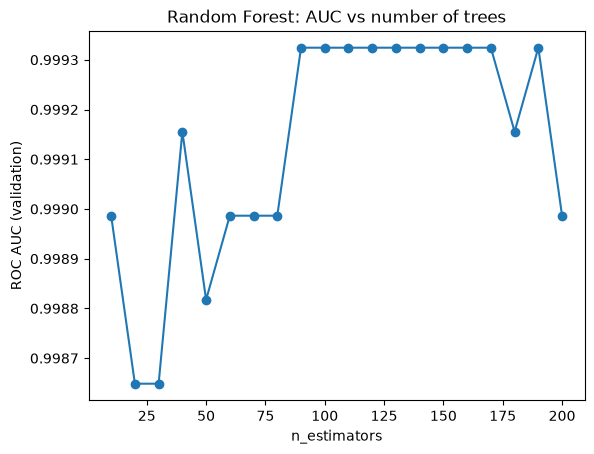

In [52]:
plt.plot(df_scores.n_estimators, df_scores.auc, marker="o")
plt.xlabel("n_estimators")
plt.ylabel("ROC AUC (validation)")
plt.title("Random Forest: AUC vs number of trees")
plt.show()

### Choosing the maximum depth of each tree

In [53]:
scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=1)
        rf.fit(X_train_scaled, y_train)

        y_pred_val_rf = rf.predict_proba(X_val_scaled)[:, 1]
        auc = roc_auc_score(y_val, y_pred_val_rf)

        scores.append((d, n, auc))

In [54]:
df_scores = pd.DataFrame(scores, columns=["max_depth", "n_estimators", "auc"])
print(df_scores.pivot(index="n_estimators", columns="max_depth", values="auc").round(4))

max_depth         5       10      15
n_estimators                        
10            0.9997  0.9990  0.9990
20            1.0000  0.9986  0.9986
30            0.9986  0.9986  0.9986
40            0.9993  0.9992  0.9992
50            0.9990  0.9988  0.9988
60            0.9993  0.9990  0.9990
70            0.9990  0.9990  0.9990
80            0.9993  0.9990  0.9990
90            0.9993  0.9993  0.9993
100           0.9990  0.9993  0.9993
110           0.9986  0.9993  0.9993
120           0.9986  0.9993  0.9993
130           0.9986  0.9993  0.9993
140           0.9986  0.9993  0.9993
150           0.9986  0.9993  0.9993
160           0.9986  0.9993  0.9993
170           0.9986  0.9993  0.9993
180           0.9986  0.9992  0.9992
190           0.9983  0.9993  0.9993
200           0.9983  0.9990  0.9990


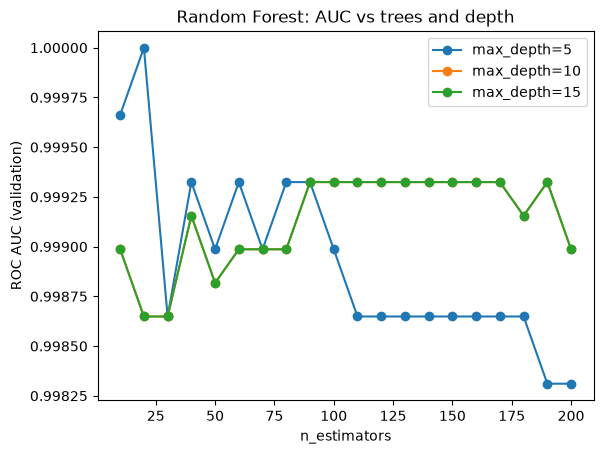

In [55]:
for d, group in df_scores.groupby("max_depth"):
    plt.plot(group.n_estimators, group.auc, marker="o", label=f"max_depth={d}")

plt.xlabel("n_estimators")
plt.ylabel("ROC AUC (validation)")
plt.title("Random Forest: AUC vs trees and depth")
plt.legend()
plt.show()

In [56]:
from sklearn.model_selection import cross_val_score

In [57]:
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=1)
scores_rf = cross_val_score(rf, X_full_train_scaled, y_full_train, cv=kfold, scoring="roc_auc")
print(f"RF AUC: {scores_rf.mean():.3f} +- {scores_rf.std():.3f}")

RF AUC: 0.993 +- 0.005


### Choosing the minimal number of observation 

In [58]:
scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators = n, max_depth=10, min_samples_leaf = s, random_state = 1)
        rf.fit(X_train_scaled, y_train)

        y_pred_val_rf = rf.predict_proba(X_val_scaled)[:, 1]
        auc = roc_auc_score(y_val, y_pred_val_rf)

        scores.append((s, n, auc))

In [59]:
df_scores = pd.DataFrame(scores, columns=["min_samples_leaf", "n_estimators", "auc"])
print(df_scores.pivot(index="n_estimators", columns="min_samples_leaf", values="auc").round(4))

min_samples_leaf      1       3       5       10      50
n_estimators                                            
10                0.9990  0.9990  0.9973  0.9939  0.9938
20                0.9986  0.9986  0.9970  0.9953  0.9946
30                0.9986  0.9980  0.9970  0.9956  0.9949
40                0.9992  0.9986  0.9970  0.9956  0.9949
50                0.9988  0.9986  0.9973  0.9956  0.9953
60                0.9990  0.9990  0.9973  0.9963  0.9949
70                0.9990  0.9986  0.9973  0.9963  0.9956
80                0.9990  0.9990  0.9976  0.9963  0.9953
90                0.9993  0.9990  0.9976  0.9966  0.9956
100               0.9993  0.9990  0.9976  0.9966  0.9956
110               0.9993  0.9983  0.9973  0.9959  0.9953
120               0.9993  0.9986  0.9973  0.9956  0.9953
130               0.9993  0.9986  0.9973  0.9956  0.9953
140               0.9993  0.9980  0.9973  0.9959  0.9953
150               0.9993  0.9980  0.9973  0.9959  0.9953
160               0.9993  0.998

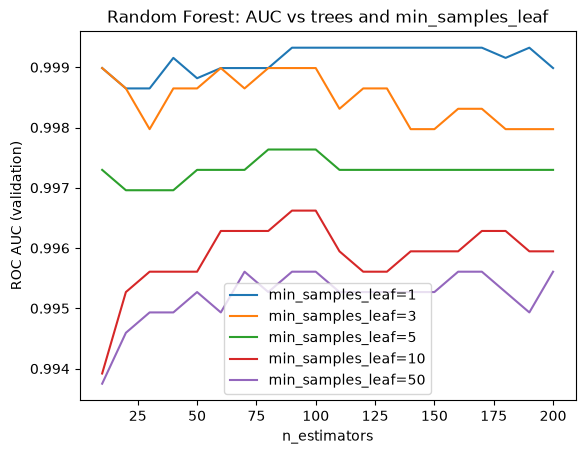

In [60]:
for s, group in df_scores.groupby("min_samples_leaf"):
    plt.plot(group.n_estimators, group.auc, label=f"min_samples_leaf={s}")

plt.xlabel("n_estimators")
plt.ylabel("ROC AUC (validation)")
plt.title("Random Forest: AUC vs trees and min_samples_leaf")
plt.legend()
plt.show()

## XGBoost

In [62]:
from xgboost import XGBClassifier

In [64]:
results = []

for n in range(10, 201, 10):
    for lr in [0.01, 0.05, 0.1, 0.3]:
        for d in [2, 3, 4, 6]:
           xgb = XGBClassifier(n_estimators = n, learning_rate = lr, max_depth = d, random_state = 1)
           xgb.fit(X_train_scaled, y_train)
           
           y_pred_val_xgb = xgb.predict_proba(X_val_scaled)[:, 1]   
           auc = roc_auc_score(y_val, y_pred_val_xgb)        
           
           results.append((n, lr, d, auc))
                            
df_xgb = pd.DataFrame(results, columns=["n_estimators", "learning_rate", "max_depth", "auc"])
print(df_xgb.sort_values("auc", ascending=False).head(10).round(4).to_string(index=False))

 n_estimators  learning_rate  max_depth  auc
           40           0.05          4  1.0
           30           0.05          4  1.0
           30           0.05          6  1.0
          160           0.01          4  1.0
          120           0.01          6  1.0
          120           0.01          4  1.0
          150           0.01          4  1.0
          140           0.01          4  1.0
          130           0.01          4  1.0
          130           0.01          6  1.0


In [66]:
print(df_xgb.groupby("learning_rate").auc.mean().round(4))
print(df_xgb.groupby("max_depth").auc.mean().round(4))
print(df_xgb.pivot_table(index="max_depth", columns="learning_rate", values="auc", aggfunc="mean").round(4))

learning_rate
0.01    0.9971
0.05    0.9985
0.10    0.9987
0.30    0.9989
Name: auc, dtype: float64
max_depth
2    0.9975
3    0.9981
4    0.9988
6    0.9988
Name: auc, dtype: float64
learning_rate    0.01    0.05    0.10    0.30
max_depth                                    
2              0.9954  0.9980  0.9982  0.9986
3              0.9964  0.9983  0.9990  0.9989
4              0.9985  0.9990  0.9988  0.9988
6              0.9983  0.9989  0.9987  0.9993


## Selecting the best model

In [67]:
from sklearn.base import clone

In [68]:
models = {"Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(solver="lbfgs", max_iter=1000, C = 1)),
        "Random forest": RandomForestClassifier(n_estimators = 100, max_depth = 10, min_samples_leaf = 1, random_state = 1),
        "XGBoost": XGBClassifier(n_estimators = 100, learning_rate = 0.05, max_depth = 4, random_state = 1)}

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_full_train_scaled, y_full_train, cv = kfold, scoring = "roc_auc")
    cv_results[name] = scores
    print(f"{name:<20} AUC: {scores.mean():.4f} +- {scores.std():.4f}")

summary = pd.DataFrame({
    "mean_auc": {k: v.mean() for k, v in cv_results.items()},
    "std_auc": {k: v.std() for k, v in cv_results.items()},
}).sort_values("mean_auc", ascending=False)
print(summary.round(4))

Logistic regression  AUC: 0.9951 +- 0.0070
Random forest        AUC: 0.9934 +- 0.0048
XGBoost              AUC: 0.9921 +- 0.0047
                     mean_auc  std_auc
Logistic regression    0.9951   0.0070
Random forest          0.9934   0.0048
XGBoost                0.9921   0.0047


In [69]:
best_name = summary.index[0]
best_mean, best_std = summary.loc[best_name, ["mean_auc", "std_auc"]]

simplicity_order = ["Logistic regression", "Random forest", "XGBoost"]
for name in simplicity_order:
    if summary.loc[name, "mean_auc"] >= best_mean - best_std:
        best_name = name
        break

print(f"\nSelected model: {best_name}")


Selected model: Logistic regression


In [71]:
final_model = clone(models[best_name])
final_model.fit(X_full_train_scaled, y_full_train)

y_pred_test = final_model.predict_proba(X_test_scaled)[:, 1]

threshold = 0.25    
decision_test = y_pred_test >= threshold

print(f"\nTest ROC AUC:  {roc_auc_score(y_test, y_pred_test):.3f}")
print(f"Test accuracy: {accuracy_score(y_test, decision_test):.3f}")
print(f"Test F2:       {fbeta_score(y_test, decision_test, beta=2):.3f}")
print(confusion_matrix(y_test, decision_test))
print(classification_report(y_test, decision_test, digits=3))


Test ROC AUC:  0.996
Test accuracy: 0.974
Test F2:       0.957
[[71  1]
 [ 2 40]]
              precision    recall  f1-score   support

           0      0.973     0.986     0.979        72
           1      0.976     0.952     0.964        42

    accuracy                          0.974       114
   macro avg      0.974     0.969     0.972       114
weighted avg      0.974     0.974     0.974       114



In [72]:
coefs = pd.Series(
    final_model.named_steps["logisticregression"].coef_[0],
    index=features,
).sort_values(key=abs, ascending=False)

print(coefs.head(10).round(3))

radius_se               1.120
radius_worst            1.089
texture_worst           1.034
area_worst              0.999
perimeter_worst         0.943
compactness_se         -0.905
concavity_worst         0.904
concave_points_worst    0.886
concave_points_mean     0.833
symmetry_worst          0.795
dtype: float64
